### Imports

In [1]:
import numpy as np
from brian2 import *
import matplotlib.pyplot as plt

### Quick test
Use this to verify that brian2 works

WARNING    Cannot use Cython, a test compilation failed: Microsoft Visual C++ 14.0 or greater is required. Get it with "Microsoft C++ Build Tools": https://visualstudio.microsoft.com/visual-cpp-build-tools/ (DistutilsPlatformError) [brian2.codegen.runtime.cython_rt.cython_rt.failed_compile_test]


INFO       Cannot use compiled code, falling back to the numpy code generation target. Note that this will likely be slower than using compiled code. Set the code generation to numpy manually to avoid this message:
prefs.codegen.target = "numpy" [brian2.devices.device.codegen_fallback]


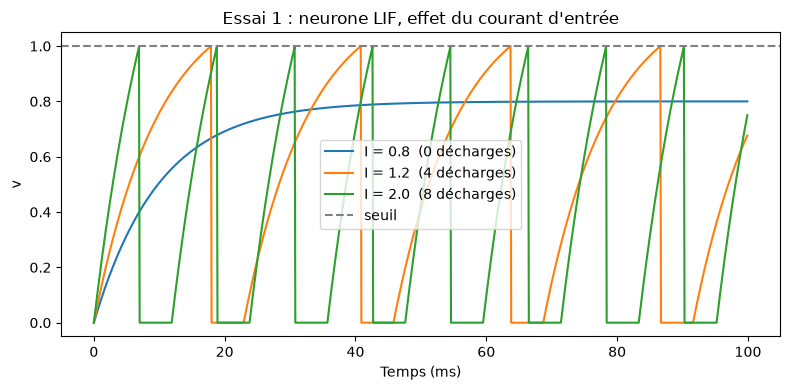

In [2]:
tau = 10*ms
eqs = '''
dv/dt = (I - v) / tau : 1 (unless refractory)
I : 1
'''

params = dict(threshold='v > 1', reset='v = 0', refractory=5*ms, method='exact')

start_scope()
G = NeuronGroup(3, eqs, **params)
G.I = [0.8, 1.2, 2.0]

M = StateMonitor(G, 'v', record=True)
S = SpikeMonitor(G)
run(100*ms)

plt.figure(figsize=(8, 4))
for k in range(3):
    plt.plot(M.t/ms, M.v[k], label=f'I = {G.I[k]:.1f}  ({S.count[k]} décharges)')
plt.axhline(1, ls='--', c='gray', label='seuil')
plt.xlabel('Temps (ms)'); plt.ylabel('v')
plt.title('Essai 1 : neurone LIF, effet du courant d\'entrée')
plt.legend(); plt.tight_layout()

## Partie I : Système non autonome
Réseau : CPG (A, B) → 8 neurones par patte (LEVER, POSER, AVANT, ARRIERE + 4 interneurones ET) + 4 neurones de virage.
Toutes les populations suivent le même modèle LIF : $	au 
rac{dv}{dt} = I + I_{biais} - v - a - g_i$, décharge si $v > 1$, puis $v = 0$, période réfractaire 2 ms.
Les synapses excitatrices font `v += w`, les inhibitrices font `gi += w` (inhibition qui décroît avec `tau_i`).

### Paramètres et modèle

In [3]:
prefs.codegen.target = 'numpy'

# ---------------------------------------------------------------- Parametres
eqs = '''
dv/dt  = (I + Ib - v - a - gi) / tau : 1 (unless refractory)
da/dt  = -a / tau_a                  : 1   # adaptation (CPG seulement)
dgi/dt = -gi / tau_i                 : 1   # inhibition synaptique
I : 1                                      # entree I_drive (CPG seulement)
Ib : 1                                     # biais (mode avant/arriere)
inc_a : 1 (constant)                       # saut d'adaptation par decharge
tau : second (constant)
tau_a : second (constant)
tau_i : second (constant)
'''
W_AB     = 4.0     # inhibition mutuelle A <-> B
W_MOT    = 1.5     # source -> LEVER/POSER, IN -> AVANT/ARRIERE (suffit seul)
W_ET     = 0.6     # source -> IN (insuffisant seul : principe du ET)
B_ET     = 0.6     # biais de mode sur les IN
W_CONTRA = 3.0     # LEVER <-> POSER, AVANT <-> ARRIERE
W_INHIB  = 3.0     # INHIB_s -> IN du cote s
TAU_BLOC = 55*ms   # inhibition lente des IN : bloque ~150 ms (~ un cycle a I_drive = 2)
DELAI    = 3*ms    # latence CPG -> pattes


def pop(n, tau=2*ms, tau_i=10*ms, tau_a=1*second, inc_a=0, Ib=0, I=0):
    """Population LIF au modele commun."""
    G = NeuronGroup(n, eqs, threshold='v > 1', reset='v = 0; a += inc_a',
                    refractory=2*ms, method='euler')
    G.tau, G.tau_i, G.tau_a, G.inc_a, G.Ib, G.I = tau, tau_i, tau_a, inc_a, Ib, I
    return G


def syn(src, tgt, w, i, j, inhib=False, delay=0*ms):
    """Synapse excitatrice (v += w) ou inhibitrice (gi += w)."""
    S = Synapses(src, tgt, on_pre=('gi_post' if inhib else 'v_post') + f' += {w}')
    S.connect(i=np.asarray(i), j=np.asarray(j))
    S.delay = delay
    return S

### Construction du réseau
Patte `i = 2k + s` (k = segment, s = 0 gauche / 1 droite), groupe `(k + s) % 2` → source swing = A (groupe 0) ou B (groupe 1).
Le CPG (adaptation forte) produit une décharge par phase : A et B alternent, et la fréquence augmente avec `I_drive`.

In [4]:
NOMS = ['LEVER', 'POSER', 'AVANT', 'ARRIERE', 'IN_sw_av', 'IN_st_ar', 'IN_sw_ar', 'IN_st_av']


def simuler(N_PAIRES=3, I_drive=2.0, mode_G='avant', mode_D='avant',
            virage_G=False, virage_D=False, n_saut=2, delta=0*ms, duree=2*second):
    start_scope()
    n = 2 * N_PAIRES                          # patte i = 2k + s
    k, s = np.arange(n) // 2, np.arange(n) % 2
    grp = (k + s) % 2                         # tripode / alternance
    sw, st = grp, 1 - grp                     # source swing / stance (0 = A, 1 = B)
    d = DELAI + k * delta                     # onde metachronale (option)
    avant = np.where(s == 0, mode_G == 'avant', mode_D == 'avant')

    cpg = pop(2, tau=10*ms, tau_i=20*ms, tau_a=200*ms, inc_a=1.5, I=I_drive)
    cpg.v, cpg.a = [0.5, 0], [0, 1]           # B part adapte -> demarre en antiphase
    P = {nom: pop(n, tau_i=TAU_BLOC if nom.startswith('IN') else 10*ms) for nom in NOMS}
    for nom in ['IN_sw_av', 'IN_st_ar']: P[nom].Ib = B_ET * avant
    for nom in ['IN_sw_ar', 'IN_st_av']: P[nom].Ib = B_ET * ~avant
    cpt = pop(2, tau=100*second)              # COMPTEUR_G, COMPTEUR_D (fuite tres lente)
    inh = pop(2)                              # INHIB_G, INHIB_D

    S = [syn(cpg, cpg, W_AB, [0, 1], [1, 0], inhib=True)]
    for nom, src in [('LEVER', sw), ('POSER', st)]:
        S.append(syn(cpg, P[nom], W_MOT, src, range(n), delay=d))
    for nom, src in [('IN_sw_av', sw), ('IN_sw_ar', sw), ('IN_st_av', st), ('IN_st_ar', st)]:
        S.append(syn(cpg, P[nom], W_ET, src, range(n), delay=d))
    for a_, b_ in [('IN_sw_av', 'AVANT'), ('IN_st_av', 'AVANT'), ('IN_sw_ar', 'ARRIERE'), ('IN_st_ar', 'ARRIERE')]:
        S.append(syn(P[a_], P[b_], W_MOT, range(n), range(n)))
    for a_, b_ in [('LEVER', 'POSER'), ('POSER', 'LEVER'), ('AVANT', 'ARRIERE'), ('ARRIERE', 'AVANT')]:
        S.append(syn(P[a_], P[b_], W_CONTRA, range(n), range(n), inhib=True))

    # Virage : chaque salve de A ajoute 1/n_saut au compteur -> 1 decharge sur n_saut
    for cote, actif in enumerate([virage_G, virage_D]):
        if actif: S.append(syn(cpg, cpt, 1 / n_saut + 0.01, [0], [cote]))
    S.append(syn(cpt, inh, W_MOT, [0, 1], [0, 1]))
    for nom in NOMS[4:]:
        S.append(syn(inh, P[nom], W_INHIB, s, range(n), inhib=True, delay=k * delta))

    M = {nom: SpikeMonitor(P[nom]) for nom in NOMS}
    M['CPG'], M['CPT'] = SpikeMonitor(cpg), SpikeMonitor(cpt)
    Network(cpg, cpt, inh, *P.values(), *S, *M.values()).run(duree)
    return {nom: (m.t / ms, np.array(m.i)) for nom, m in M.items()} | {'n': n, 'duree': duree / ms}

### Décodage des décharges en mouvement (hors réseau)
Contact entre POSER et LEVER ; AVANT/ARRIERE fixent la position ; une poussée = passage avant → arrière au sol (+d) ou arrière → avant (−d).
Chaque patte porte `d / N_PAIRES` pour que la vitesse ne dépende pas du nombre de pattes. Chaque poussée d'un côté fait avancer le corps de `ds/2` et tourner de `±ds/L`.

In [5]:
def decoder(R, d=0.2, L=1.0):
    """Decodage hors reseau : contact, position, poussees -> trajectoire (x, y, theta)."""
    n = R['n']
    ev = []                                   # (temps, patte, commande)
    for c in ['LEVER', 'POSER', 'AVANT', 'ARRIERE']:
        t, i = R[c]
        ev += [(tt, ii, c) for tt, ii in zip(t, i)]
    ev.sort()
    sol, pos = np.zeros(n, bool), np.zeros(n, int)   # pos : +1 avant, -1 arriere
    x = y = th = 0.0
    traj, contact = [(0, 0, 0, 0)], [[] for _ in range(n)]
    for t, i, c in ev:
        if c == 'POSER' and not sol[i]: sol[i] = True; contact[i].append([t, R['duree']])
        elif c == 'LEVER' and sol[i]: sol[i] = False; contact[i][-1][1] = t
        elif c in ('AVANT', 'ARRIERE'):
            new = 1 if c == 'AVANT' else -1
            if sol[i] and pos[i] == -new:           # poussee au sol
                ds = d / (n // 2) * (-new)           # +d si avant -> arriere
                th += ds / L * (1 if i % 2 else -1)  # cote D -> +theta (gauche)
                x += ds / 2 * np.cos(th); y += ds / 2 * np.sin(th)
                traj.append((t, x, y, th))
            pos[i] = new
    return np.array(traj), contact


def afficher(R, titre):
    """Raster du CPG, diagramme de demarche (barres = patte au sol) et trajectoire."""
    traj, contact = decoder(R)
    n = R['n']
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), gridspec_kw={'width_ratios': [1, 2, 1]})
    t, i = R['CPG']
    ax[0].plot(t, i, '|', ms=20, c='k')
    ax[0].set(yticks=[0, 1], yticklabels=['A', 'B'], xlabel='Temps (ms)', title='CPG', xlim=(0, 1000))
    pattes = range(n) if n <= 12 else range(0, n, 2)       # grand N : cote gauche seulement
    for r, p in enumerate(pattes):                           # couleur = groupe du CPG (k + s) % 2
        ax[1].broken_barh([(a, b - a) for a, b in contact[p]], (r - 0.4, 0.8), color=f'C{(p // 2 + p % 2) % 2}')
    ax[1].set(yticks=range(n) if n <= 12 else [], ylabel='Patte' if n <= 12 else 'Pattes gauches (avant -> arriere)',
              xlabel='Temps (ms)', title='Diagramme de demarche (barre = patte au sol)')
    if n <= 12: ax[1].set_yticklabels([f"{'GD'[p % 2]}{p // 2 + 1}" for p in pattes])
    ax[1].invert_yaxis()
    ax[2].plot(traj[:, 1], traj[:, 2]); ax[2].plot(0, 0, 'ko')
    ax[2].set_aspect('equal', adjustable='datalim'); ax[2].set(xlabel='x', ylabel='y', title='Trajectoire')
    fig.suptitle(titre); plt.tight_layout(); plt.show()
    return traj

### 1.3.1 Marche avant et 1.3.3 Ligne droite
Tripode : G1, D2, G3 alternent avec D1, G2, D3. Autant de poussées à gauche qu'à droite → θ revient à 0 (seulement un léger dandinement du tripode).

WARNING    'tau' is an internal variable of group 'neurongroup_10', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_11', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_2', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


...

WARNING    'tau' is an internal variable of group 'neurongroup_5', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_6', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_7', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_8', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_9', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


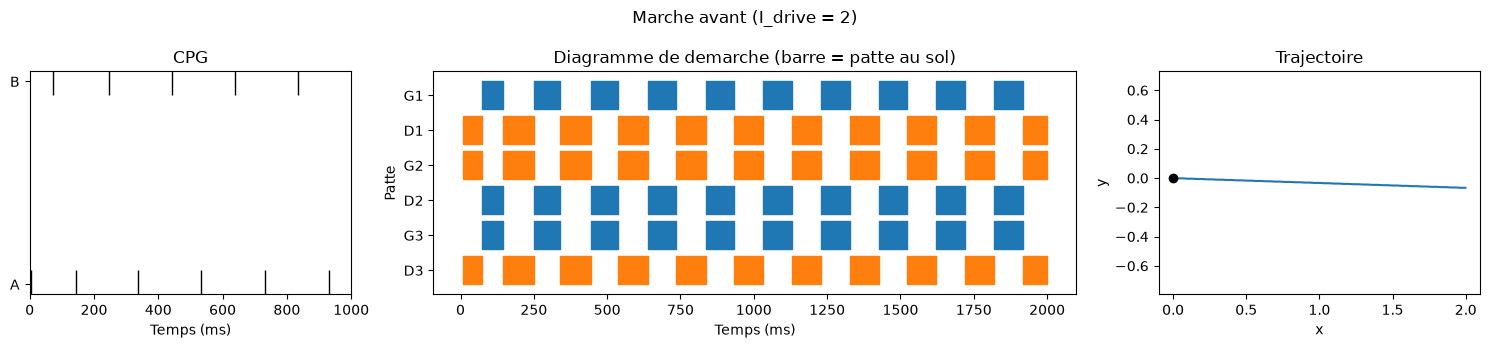

Position finale : x = 2.00, y = -0.07, theta = 0.00 rad


In [6]:
R = simuler(mode_G='avant', mode_D='avant')
traj = afficher(R, 'Marche avant (I_drive = 2)')
print(f"Position finale : x = {traj[-1, 1]:.2f}, y = {traj[-1, 2]:.2f}, theta = {traj[-1, 3]:.2f} rad")

### 1.3.2 Marche arrière
Même rythme du CPG, seul le biais des interneurones change (IN_sw_ar et IN_st_av).

WARNING    'tau' is an internal variable of group 'neurongroup_12', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_13', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_14', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_15', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_16', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


...

WARNING    'tau' is an internal variable of group 'neurongroup_18', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_19', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_20', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_21', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'tau' is an internal variable of group 'neurongroup_22', but also exists in the run namespace with the value 10. * msecond. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


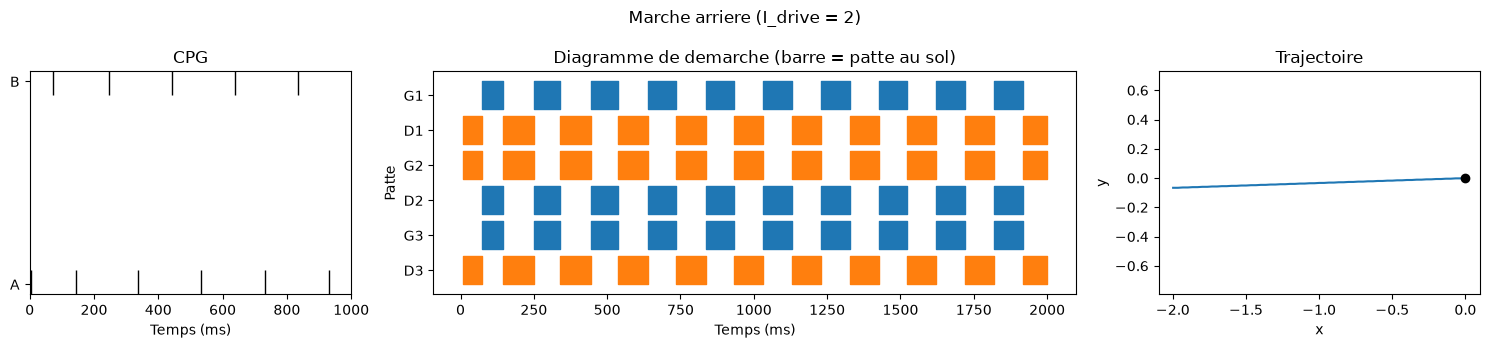

In [7]:
R = simuler(mode_G='arriere', mode_D='arriere')
traj = afficher(R, 'Marche arriere (I_drive = 2)')

### 1.3.4 Variation de la vitesse
On change seulement `I_drive` : la fréquence du CPG, donc le nombre de poussées par seconde, augmente.

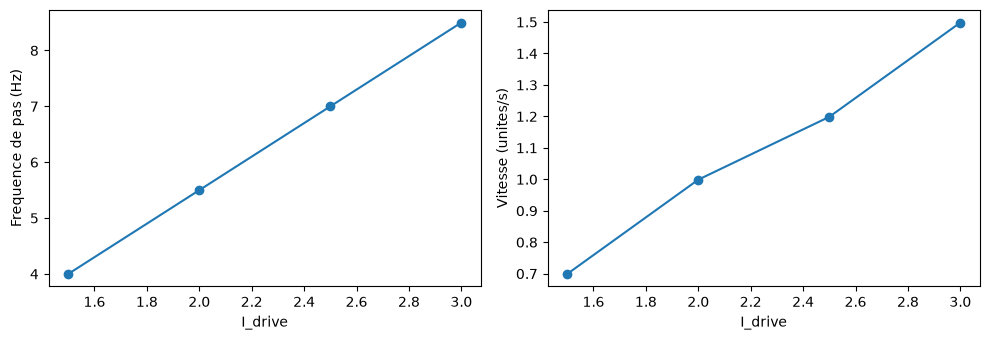

In [8]:
I_vals = [1.5, 2.0, 2.5, 3.0]
freq, vit = [], []
for I_d in I_vals:
    R = simuler(I_drive=I_d)
    traj = decoder(R)[0]
    freq.append(np.sum(R['CPG'][1] == 0) / (R['duree'] / 1000))   # salves de A par seconde
    vit.append(traj[-1, 1] / (R['duree'] / 1000))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(I_vals, freq, 'o-'); ax[0].set(xlabel='I_drive', ylabel='Frequence de pas (Hz)')
ax[1].plot(I_vals, vit, 'o-'); ax[1].set(xlabel='I_drive', ylabel='Vitesse (unites/s)')
plt.tight_layout(); plt.show()

### 1.3.5 Rotation sur place
`mode_G = avant`, `mode_D = arriere` → $v_G = -v_D$, donc $v = 0$ et le corps tourne (vers la droite).

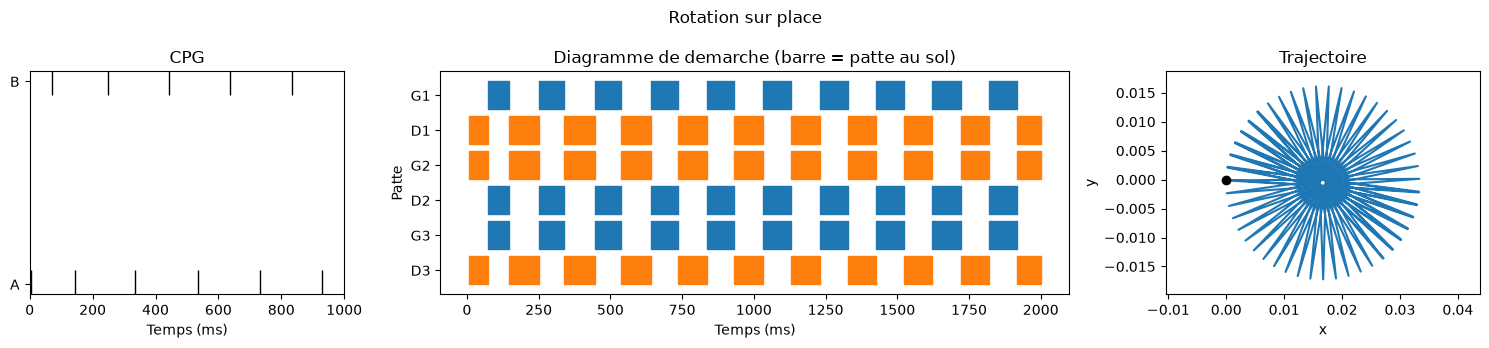

Position finale : x = 0.03, y = -0.01, theta = -4.00 rad


In [9]:
R = simuler(mode_G='avant', mode_D='arriere')
traj = afficher(R, 'Rotation sur place')
print(f"Position finale : x = {traj[-1, 1]:.2f}, y = {traj[-1, 2]:.2f}, theta = {traj[-1, 3]:.2f} rad")

### 1.3.6 Déplacement en cercle
`virage_D` actif : COMPTEUR_D décharge une salve de A sur `n_saut`, INHIB_D bloque les interneurones de direction droits pendant ~un cycle. Rayon théorique $R = (L/2)(2n - 1)$, rayon mesuré = distance parcourue / |angle total|.

n_saut = 1 : R theorique = 0.50 L, R mesure = 0.50 L


n_saut = 2 : R theorique = 1.50 L, R mesure = 1.50 L


n_saut = 3 : R theorique = 2.50 L, R mesure = 2.55 L


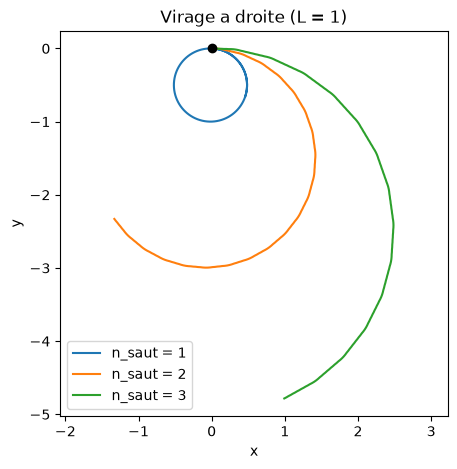

In [10]:
plt.figure(figsize=(5, 5))
for n_s in [1, 2, 3]:
    R = simuler(virage_D=True, n_saut=n_s, duree=8*second)
    traj = decoder(R)[0]
    dist = np.sum(np.hypot(np.diff(traj[:, 1]), np.diff(traj[:, 2])))
    print(f"n_saut = {n_s} : R theorique = {0.5 * (2 * n_s - 1):.2f} L, R mesure = {dist / abs(traj[-1, 3]):.2f} L")
    plt.plot(traj[:, 1], traj[:, 2], label=f'n_saut = {n_s}')
plt.plot(0, 0, 'ko'); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y')
plt.title('Virage a droite (L = 1)'); plt.legend(); plt.show()

### 1.3.7 Généralisation à N paires de pattes
On change seulement `N_PAIRES`. Le délai optionnel `delta` (k·Δ par segment) crée une onde métachronale le long du corps.

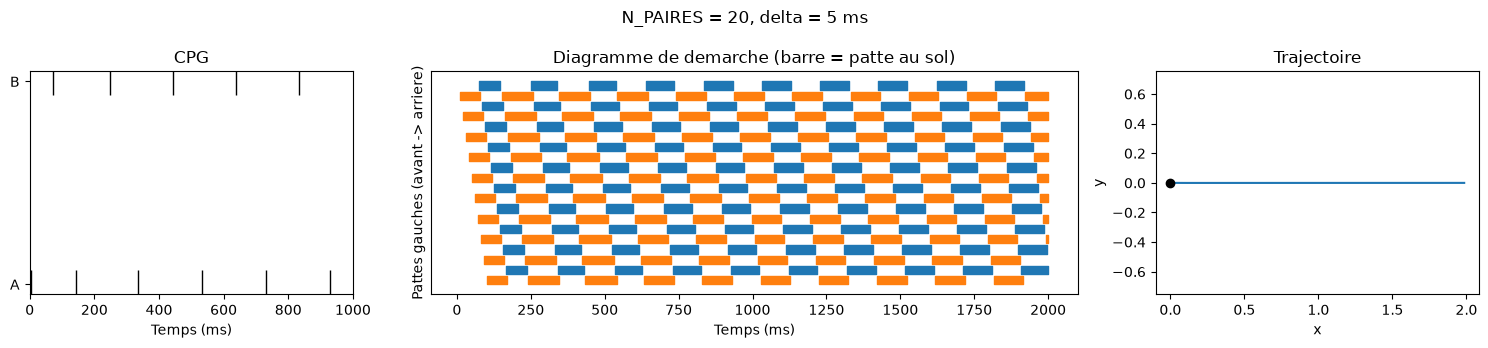

In [11]:
R = simuler(N_PAIRES=20, delta=5*ms)
afficher(R, 'N_PAIRES = 20, delta = 5 ms');

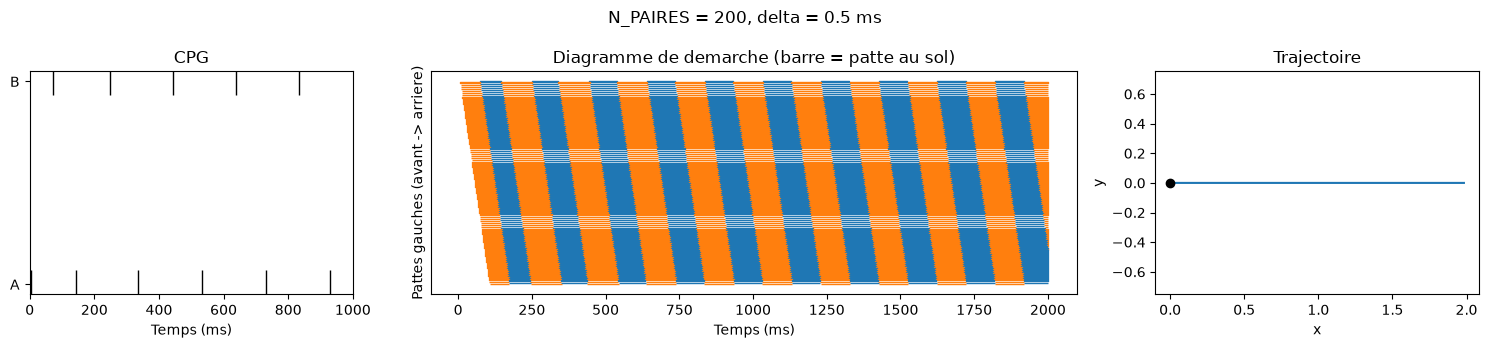

In [12]:
R = simuler(N_PAIRES=200, delta=0.5*ms)
afficher(R, 'N_PAIRES = 200, delta = 0.5 ms');